# Chapter 2: End to end machine learning project

## Pipelines

Pipelines are a way to streamline a lot of the routine processes in machine learning. They allow you to bundle together multiple steps into a single object. This is especially useful for ensuring that the same transformations are applied to both the training and test datasets. A pipeline consists of the following components:

1. **Preprocessing**: This step involves cleaning and transforming the data, such as handling missing values, encoding categorical variables, and scaling features.
2. **Modeling**: This step involves selecting and training a machine learning model on the preprocessed data.
3. **Evaluation**: This step involves assessing the performance of the trained model using appropriate metrics.
4. **Prediction**: This step involves using the trained model to make predictions on new, unseen data.
5. **Deployment**: This step involves deploying the trained model into a production environment where it can be used to make predictions on real-world data.
6. **Monitoring**: This step involves continuously monitoring the performance of the deployed model to ensure it remains accurate and reliable over time.
7. **Maintenance**: This step involves updating the model as needed, such as retraining it with new data or adjusting its parameters to improve performance.
8. **Documentation**: This step involves documenting the entire machine learning pipeline, including the data preprocessing steps, model selection process, evaluation metrics, and deployment procedures. This documentation is essential for ensuring that the pipeline can be easily understood and maintained by other team members or future developers.
9. **Version Control**: This step involves using version control systems to track changes to the code, data, and models used in the pipeline. This allows for easy collaboration among team members and ensures that previous versions of the pipeline can be restored if needed.


In [72]:
from pathlib import Path
import numpy as np
import pandas as pd
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing = load_housing_data()

## Quick explore of the data

In [73]:
# handy funcs.
housing.head()
housing.describe()
housing['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

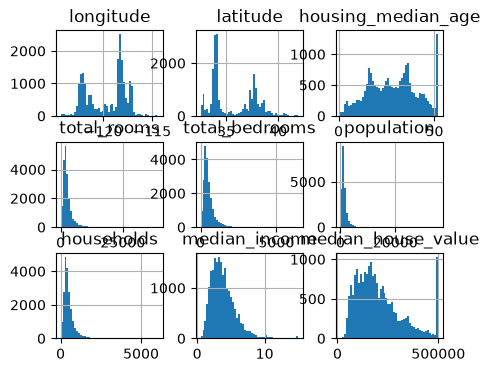

In [74]:
import matplotlib.pyplot as plt

housing.hist(bins=50, figsize=(5,4))

## Create a test set

Danger that if you explore data before creating a test set you fit the test data too well and then the true performance of the model will be overestimated.
sklearns train_test_split splits data by shuffling with the use of the random_state_parameter and then splitting.

In [75]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)


Randomly splitting runs the risk of introducing bias into the test set. It is also important that the test set is representative of the production data. e.g think about voters need right balance of men and women, young and old, etc. If you are going to group data need to make sure that each group is big enough to be representative. Each group needs enough instances in it. 

Text(0, 0.5, 'Number of districts')

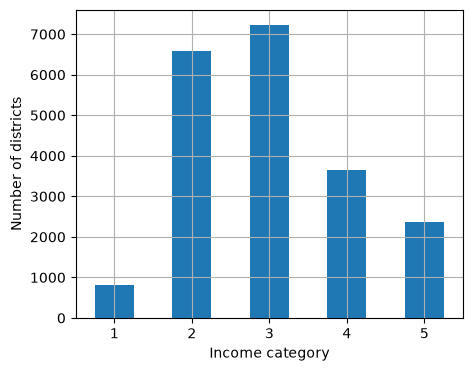

In [76]:
housing["income_cat"] = pd.cut(housing["median_income"],bins=[0., 1.5, 3.0, 4.5, 6., np.inf],labels=[1,2,3,4,5])
plt.figure(figsize=(5,4))
housing["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")

In [77]:
# can split data using stratified groups so you can do multiple rounds of validation
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

strat_splits = []
for train_index, test_index in splitter.split(housing, housing["income_cat"]):
    strat_train_set_n = housing.iloc[train_index]
    strat_test_set_n = housing.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])



In [78]:
# Equivalently you can use this shorthand if you are happy with n_splits=1
#from sklearn.model_selection import train_test_split

#train_set, test_set = train_test_split(housing, test_size=0.2, stratify=housing["income_cat"],random_state=42)


In [79]:
strat_train_set, strat_test_set = strat_splits[0]
strat_test_set

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat
3905,-121.95,37.11,21.0,2387.0,357.0,913.0,341.0,7.7360,397700.0,<1H OCEAN,5
16821,-118.01,33.89,36.0,1589.0,265.0,804.0,272.0,4.6354,202900.0,<1H OCEAN,4
2900,-118.18,33.74,30.0,5915.0,1750.0,2136.0,1503.0,4.0968,310000.0,NEAR OCEAN,3
7193,-122.48,37.74,52.0,2166.0,423.0,1072.0,370.0,4.1310,314300.0,NEAR OCEAN,3
13928,-122.39,37.78,5.0,1405.0,515.0,725.0,392.0,3.6037,187500.0,NEAR BAY,3
...,...,...,...,...,...,...,...,...,...,...,...
12369,-124.16,40.79,46.0,3042.0,597.0,1206.0,541.0,2.1135,90600.0,NEAR OCEAN,2
8707,-119.01,35.39,29.0,1820.0,459.0,1134.0,419.0,1.8289,59400.0,INLAND,2
16634,-123.01,38.67,33.0,914.0,147.0,394.0,132.0,4.6875,246200.0,<1H OCEAN,4
9779,-122.03,37.60,24.0,2077.0,383.0,1488.0,389.0,4.5721,214700.0,NEAR BAY,4


In [80]:
strat_test_set["income_cat"].value_counts()/len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [81]:
#drop a column : inplace =True deprecated
for set_ in (strat_train_set, strat_test_set):
    set_=set_.drop("income_cat", axis=1)

In [82]:
housing=strat_train_set.copy()

<Axes: xlabel='longitude', ylabel='latitude'>

<Figure size 500x400 with 0 Axes>

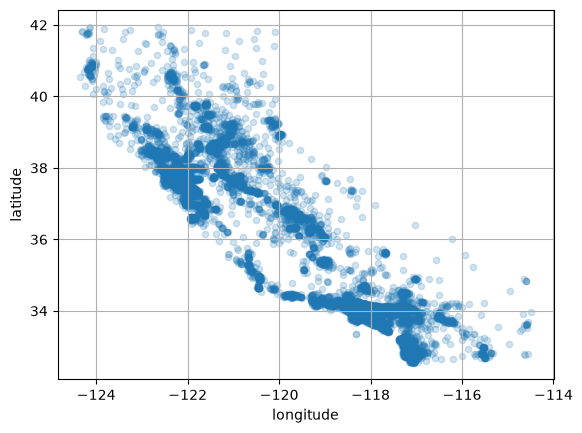

In [83]:
plt.figure(figsize=(5,4))
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2)

<Axes: xlabel='longitude', ylabel='latitude'>

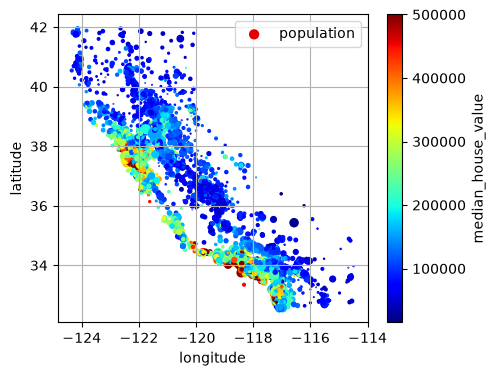

In [84]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True, s=housing["population"]/200, label="population",c="median_house_value", cmap="jet", colorbar=True, legend=True, sharex=False, figsize=(5,4))

In [85]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=True)

latitude             -0.139584
longitude            -0.050859
population           -0.020153
total_bedrooms        0.054635
households            0.071426
housing_median_age    0.102175
total_rooms           0.137455
median_income         0.688380
median_house_value    1.000000
Name: median_house_value, dtype: float64

### Scatter Matrix

Choose which variables to look for correlations. N.B the points where a var is plotted against itself it instead plots a histogram.

array([[<Axes: xlabel='median_house_value', ylabel='median_house_value'>,
        <Axes: xlabel='median_income', ylabel='median_house_value'>,
        <Axes: xlabel='total_rooms', ylabel='median_house_value'>,
        <Axes: xlabel='housing_median_age', ylabel='median_house_value'>],
       [<Axes: xlabel='median_house_value', ylabel='median_income'>,
        <Axes: xlabel='median_income', ylabel='median_income'>,
        <Axes: xlabel='total_rooms', ylabel='median_income'>,
        <Axes: xlabel='housing_median_age', ylabel='median_income'>],
       [<Axes: xlabel='median_house_value', ylabel='total_rooms'>,
        <Axes: xlabel='median_income', ylabel='total_rooms'>,
        <Axes: xlabel='total_rooms', ylabel='total_rooms'>,
        <Axes: xlabel='housing_median_age', ylabel='total_rooms'>],
       [<Axes: xlabel='median_house_value', ylabel='housing_median_age'>,
        <Axes: xlabel='median_income', ylabel='housing_median_age'>,
        <Axes: xlabel='total_rooms', ylabel='housi

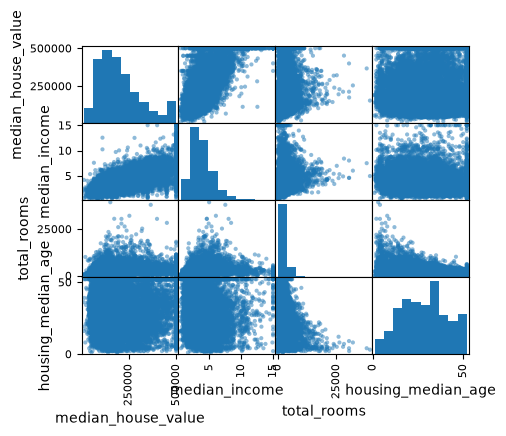

In [86]:
from matplotlib.pyplot import scatter
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]

scatter_matrix(housing[attributes], figsize=(5,4))

<Axes: xlabel='median_income', ylabel='median_house_value'>

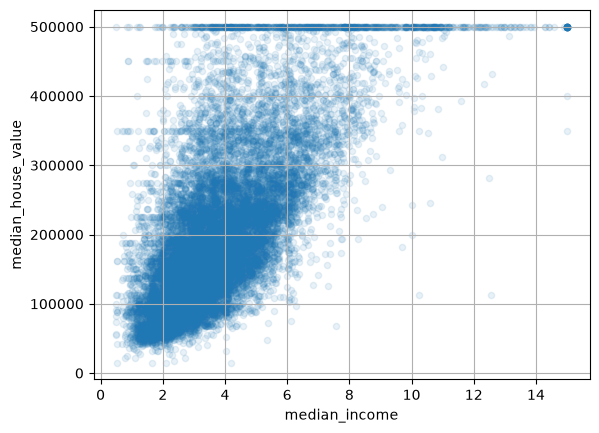

In [87]:
housing.plot(kind="scatter", x="median_income", y="median_house_value", alpha=0.1, grid=True)

There are more complicated correlations between data such as u shaped relationships. Some data attributes may be skewed. One way to compensate for this is to use log transformations.

Also want to consider what combinations of attributes may be most important. For example, in the housing data, the combination of total rooms and total bedrooms may be more important than either attribute alone. This can be done by creating new features that combine existing attributes.

In [88]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

## Prepare the data for Machine Learning Algorithms

create functions so that you can create a reproducible pipeline. Build a libray of useful ones. 
Separate the predictors from the labels (e,g, median_house_value)

In [89]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

In [90]:
# Missing features
#option 1 - If there are missing values in the total_bedrooms column then drop that row
#housing = housing.dropna(subset=["total_bedrooms"])

#option 2 - Drop the column total_bedrooms completely
#housing.drop("total_bedrooms", axis=1)

#option 3 - fill missing values with a designated value
median=housing["total_bedrooms"].median()
housing["total_bedrooms"] = housing["total_bedrooms"].fillna(median)


We can "impute" missing values using the median, mean, or most frequent value. The median is often a good choice because it is less sensitive to outliers than the mean. Frequent value can be used with categorical data. There also exist more sophisticated imputation techniques:
- K-nearest neighbors imputation: looks at k nearest neighbours for the value.
- Iterative Imputer which trains a regression model to predict missing value based on other features. This is repeated for each feature with missing values until convergence.

In [91]:
# Alternative to the manual approach above use
from sklearn.impute import SimpleImputer

imputer=SimpleImputer(strategy="median")

#only use numerical columns
housing_num = housing.select_dtypes(include=[np.number])
imputer.fit(housing_num)


,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](8,)","[-118.51, 34.26, 29. ,...,1167. , 408. , 3.54]"


In [92]:
# This is the same as housing_num.median().values
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [93]:
# Apply imputer to all columns
imputer.transform(housing_num)

array([[-1.2242e+02,  3.7800e+01,  5.2000e+01, ...,  1.5760e+03,
         1.0340e+03,  2.0987e+00],
       [-1.1838e+02,  3.4140e+01,  4.0000e+01, ...,  6.6600e+02,
         3.5700e+02,  6.0876e+00],
       [-1.2198e+02,  3.8360e+01,  3.3000e+01, ...,  5.6200e+02,
         2.0300e+02,  2.4330e+00],
       ...,
       [-1.1706e+02,  3.2590e+01,  1.3000e+01, ...,  2.8140e+03,
         7.6000e+02,  4.0616e+00],
       [-1.1840e+02,  3.4060e+01,  3.7000e+01, ...,  1.7250e+03,
         8.3800e+02,  4.1455e+00],
       [-1.2241e+02,  3.7660e+01,  4.4000e+01, ...,  6.8200e+02,
         2.1200e+02,  3.2833e+00]], shape=(16512, 8))

Scikit learn provides Estimators, Transformers and Predictors:
- An estimator is any object that can estimate a parameter based on a dataset; it implements a fit method.
- A transformer is an estimator that can also transform a dataset; it implements a transform method.
- A predictor is an estimator that can make predictions, e.g. linear regression, decision trees. It always has a predict method and often a score method as well.

hyperparameters are public instance vars eg imputer.strategy. learned parameters are private instance vars eg imputer.statistics_.
sklearn outputs numpy or sparse scipy arrays but not pandas dataframes. To resolve this issue for a pipeline start with:

```python
from sklearn.pipeline import Pipeline

# Build your pipeline or preprocessing steps
preprocessing_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    # ... other steps ...
])

# Force the entire pipeline to return pandas DataFrames
preprocessing_pipeline.set_output(transform="pandas")
```

## Categorical data

To work with categorical data it is worth encoding it. 

In [99]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_cat = housing[["ocean_proximity"]]
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
print(housing_cat_encoded[:8])
ordinal_encoder.categories_

[[3.]
 [0.]
 [1.]
 [1.]
 [4.]
 [1.]
 [0.]
 [3.]]


[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

The danger here is the numbers imply an ordered relationship which may not be true. One hot encoding is a way to avoid this. It creates a new binary column for each category and returns a sparse matrix. A sparse matrix is a memory efficient way to store data that contains a lot of zeros. It only stores the non-zero values and their corresponding indices, which can save a significant amount of memory when working with large datasets. This can still start to get very memory intensive for lots of categories. Might be better to replace with a number such as distance to ocean.

In [101]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
print(housing_cat_1hot)
cat_encoder.categories_

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>
  Coords	Values
  (0, 3)	1.0
  (1, 0)	1.0
  (2, 1)	1.0
  (3, 1)	1.0
  (4, 4)	1.0
  (5, 1)	1.0
  (6, 0)	1.0
  (7, 3)	1.0
  (8, 0)	1.0
  (9, 0)	1.0
  (10, 1)	1.0
  (11, 0)	1.0
  (12, 0)	1.0
  (13, 1)	1.0
  (14, 4)	1.0
  (15, 0)	1.0
  (16, 1)	1.0
  (17, 3)	1.0
  (18, 1)	1.0
  (19, 0)	1.0
  (20, 0)	1.0
  (21, 4)	1.0
  (22, 1)	1.0
  (23, 3)	1.0
  (24, 1)	1.0
  :	:
  (16487, 1)	1.0
  (16488, 0)	1.0
  (16489, 0)	1.0
  (16490, 3)	1.0
  (16491, 1)	1.0
  (16492, 4)	1.0
  (16493, 4)	1.0
  (16494, 1)	1.0
  (16495, 0)	1.0
  (16496, 1)	1.0
  (16497, 0)	1.0
  (16498, 0)	1.0
  (16499, 4)	1.0
  (16500, 0)	1.0
  (16501, 0)	1.0
  (16502, 0)	1.0
  (16503, 0)	1.0
  (16504, 0)	1.0
  (16505, 0)	1.0
  (16506, 1)	1.0
  (16507, 0)	1.0
  (16508, 1)	1.0
  (16509, 4)	1.0
  (16510, 0)	1.0
  (16511, 4)	1.0


[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

## Feature scaling

ML algorithms don't perform well when inputs have very different scales. For example, a house's total rooms may be in the hundreds while its median income may be in the tens of thousands. This can cause some algorithms to give more weight to certain features over others, leading to biased results. This requires scaling and standardization. Fit the scalers to the training data only and then apply the same transformation to the test data. This might require you to clip outliers in your new data.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

#linear scaling between min and max
min_max_scaler = MinMaxScaler(feature_range=(-1,1))
housing_min_max_scaled = min_max_scaler.fit_transform(housing_num)
# std subtracts mean and divides by std
std_scaler = MinMaxScaler(feature_range=(-1,1))
housing_std_scaled = std_scaler.fit_transform(housing_num)
# 

For distributions with heavy tails it is best to transform before scaling to make the distribution more symmetric.You can take the sqrt() or log() of the data. Alternatively you can bucketize the data into buckets with equal numbers of samples scaling from 0-1. This is good for multimodal distributions.Another strategy for multimodal distributions is to build a new feature that is the distance to the nearest mode. This can be done by clustering the data and then calculating the distance to the nearest cluster center.sklearn's rbf_kernel()

In [103]:
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(housing[["housing_median_age"]], [[35]], gamma=0.1)

As well as transforming inputs we sometimes need to transform outputs. For example if the target distribution has a heavy tail we can take the log of the target. This will make the distribution more symmetric and easier to predict. When we make predictions we will need to take the exp() of the predictions to get back to the original scale. sklearn has inverse transformers for this purpose.

In [ ]:
#scaling output and inverting the scaling afterwards
from sklearn.linear_model import LinearRegression

target_scaler=StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model=LinearRegression()
model.fit(housing["median_income"], scaled_labels)
some_new_data = housing[["median_income"]].iloc[:5] # pretend this is new data
scaled_predictions = model.predict(some_new_data)
predictions=target_scaler.inverse_transform(scaled_predictions)

In [ ]:
# Or more simply which handles some of the transforming backwards and forwards.
from sklearn.compose import TransformedTargetRegressor

model=TransformedTargetRegressor(LinearRegression(),transformer=StandardScaler())
model.fit(housing[["median_income"]], housing_labels)
predictions=model.predict(some_new_data)

### Building your own transformers

just provide a function. This is for transformers that don't need training.

In [112]:
from pyclbr import Function

from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]])

# Can create functions that take hyperparameters
rbf_transformer = FunctionTransformer(rbf_kernel, kw_args=dict(Y=[[35]], gamma=0.1))
age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])

# Measure similarity between a feature and San Francisco
sf_coords = 37.7749, -122.41
sf_transformer = FunctionTransformer(rbf_kernel, kw_args=dict(Y=[sf_coords], gamma=0.1))
sf_simil=sf_transformer.transform(housing[["latitude", "longitude"]])

# Calculate ratios in transformer
ratio_transformer = FunctionTransformer(lambda X: X[:, [0]]/X[:,[1]])
ratio_transformer.transform(np.array([[1,2],[3,4]]))

array([[0.5 ],
       [0.75]])

### Custom transformers that need training

ie use a fit method before then transforming. For example, a transformer that imputes missing values based on the median of the training data would need to calculate the median during the fit step and then use that value during the transform step. You can get fit_transform() by inheriting the base class TransformerMixin. BaseEstimator can also be inherited to get get_params() and set_params() methods.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

# Note we validate the inputs
# Scikit pipelines always have two methods X and Y even if we ignore Y
# Set the learned params in fit and then transform or predict check this has happened.
# To complete everything should have a feature_names_in_ in the fit() and should have a get_feature_names_out() and an inverse_transform() methods.
class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):
        self.with_mean=with_mean

    def fit(self, X, y=None):
        X=check_array(X)
        self.mean_=X.mean(axis=0)
        self.scale=X.std(axis=0)
        self.n_features_in_=X.shape[1]
        return self #always return self

    def transform(self, X):
        check_is_fitted(self)
        X=check_array(X)
        assert self.n_features_in_ == X.shap[1]
        if self.with_mean_:
            X=X - self.mean_
            return X / self.scale_